# Week 9: Option Greeks & Risk Sensitivities

How can a call lose money when its stock goes up? We will derive the five main Greeks from last week's Black–Scholes formula, use delta to size a stock hedge, and check one price move in Python.

[Week 8 notebook](https://github.com/novaquantclub/quant-roadmap/blob/main/Week%208/Week_8_Options_Final_Executed.ipynb) · [Quant Roadmap](https://github.com/novaquantclub/quant-roadmap)

## 1. From the binomial hedge ratio to delta

Revisit a one-step tree. The stock is \$100 today and can finish at \$120 or \$80. A call with strike \$95 pays \$25 or \$0. Subtract the two replication equations. The bond pays the same in both states, so it drops out:

$$
\Delta_{\mathrm{tree}}=\frac{C_u-C_d}{S_u-S_d}=\frac{25-0}{120-80}=0.625.
$$

The replicating portfolio holds 0.625 shares per option share. In Black–Scholes, spot varies continuously, so the hedge ratio is the **local slope** $\Delta=\partial C/\partial S$. Gamma tells us how quickly that slope changes.

## 2. Derive delta and gamma

Start with a European call on a stock that pays no dividends. $S$ is spot, $K$ is the strike (called $X$ in Week 8), $T$ is time remaining in years, $r$ is the continuously compounded annual rate, and $\sigma$ is annual volatility. $N$ is the standard normal CDF and $\phi=N'$ is its density.

$$
C=S N(d_1)-Ke^{-rT}N(d_2),\qquad
d_1=\frac{\ln(S/K)+(r+\tfrac12\sigma^2)T}{\sigma\sqrt{T}},\qquad
d_2=d_1-\sigma\sqrt{T}.
$$

**Why the chain-rule terms cancel.** From the normal density,

$$
\frac{\phi(d_1)}{\phi(d_2)}
=e^{-(d_1^2-d_2^2)/2}
=e^{-d_1\sigma\sqrt T+\sigma^2T/2}
=e^{-\ln(S/K)-rT}.
$$

Therefore $S\phi(d_1)=Ke^{-rT}\phi(d_2)$. Holding $K,T,r,\sigma$ fixed, both $d_1$ and $d_2$ change by the same amount when we bump spot because $d_1-d_2=\sigma\sqrt T$ is constant in spot. Differentiate the call price:

$$
\begin{aligned}
\Delta=\frac{\partial C}{\partial S}
&=N(d_1)+S\phi(d_1)\frac{\partial d_1}{\partial S}
-Ke^{-rT}\phi(d_2)\frac{\partial d_2}{\partial S}\\
&=N(d_1).
\end{aligned}
$$

Now differentiate delta. The derivative of $\ln(S/K)$ with respect to spot is $1/S$, so

$$
\Gamma=\frac{\partial \Delta}{\partial S}
=\phi(d_1)\frac{\partial d_1}{\partial S}
=\frac{\phi(d_1)}{S\sigma\sqrt T}.
$$

**Read the numbers.** The Week 8 call has $\Delta\approx0.6665$ and $\Gamma\approx0.01455$. A long contract on 100 shares has the same initial spot exposure as about 66.65 shares. Shorting that many shares offsets the initial delta. After a \$1 spot-only rise, positive gamma says to short roughly 1.45 more shares to restore the hedge.

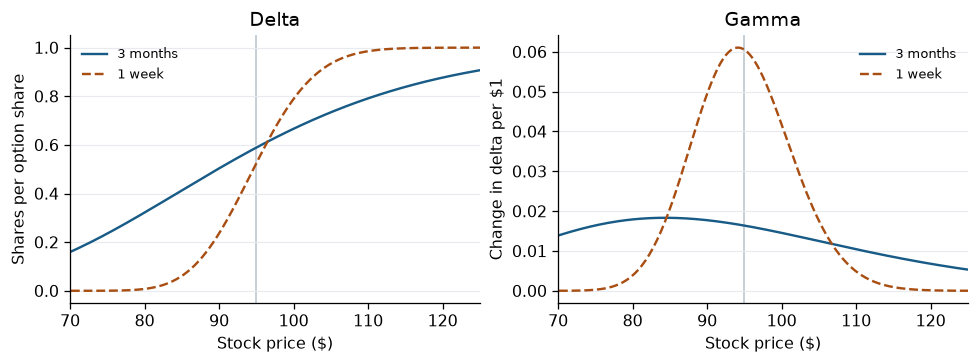

The vertical line marks the \$95 strike. With one week left, delta rises more sharply near the strike, so gamma is higher there. Where would the hedge go stale fastest?

## 3. Derive vega, theta and rho

Write $B=Ke^{-rT}$ for the discounted strike. The same identity combines the two chain-rule terms into a single term. With $K$ fixed,

$$
dC=N(d_1)\,dS-N(d_2)\,dB+S\phi(d_1)\,d(d_1-d_2).
$$

For each Greek below, move one input at a time and hold the rest fixed.

**Vega.** The discounted strike stays fixed. Since $d_1-d_2=\sigma\sqrt T$, its volatility derivative is $\sqrt T$.

$$
\frac{\partial C}{\partial \sigma}=S\phi(d_1)\sqrt T.
$$

Vega is positive for a long call. Divide this derivative by 100 to quote the change in premium for **one percentage point** of volatility, such as 50% to 51%.

**Theta.** Both terms move with time remaining: $\partial B/\partial T=-rB$ and $\partial(d_1-d_2)/\partial T=\sigma/(2\sqrt T)$. Calendar time passing makes $T$ fall, so reverse the sign of the derivative with respect to remaining time.

$$
\Theta_{\mathrm{year}}=-\frac{\partial C}{\partial T}
=-rKe^{-rT}N(d_2)-\frac{S\phi(d_1)\sigma}{2\sqrt T}.
$$

Divide by 365 for an estimate **per calendar day**. With the other inputs fixed, one day passing costs this call about \$0.064 per share.

**Rho.** The gap between $d_1$ and $d_2$ stays fixed. The rate changes the discounted strike through $\partial B/\partial r=-TB$.

$$
\rho_{\mathrm{decimal}}=\frac{\partial C}{\partial r}
=TKe^{-rT}N(d_2).
$$

A higher rate lowers the present value of the strike the call holder would pay. Divide by 100 for rho **per percentage point** of the annual rate.

**What about puts and dividends?** With no dividends, put–call parity is $P=C-S+B$. The put's delta is therefore $\Delta_{\mathrm{call}}-1$, its gamma and vega match the call's, and its rho is negative. Put theta can have either sign. Lab 9 adds a continuous dividend yield $q$ to the model. Holding the other inputs fixed, a higher yield lowers call value and raises put value.

### Put Greeks from put–call parity

For a European call and put on the same non-dividend-paying stock, with the same strike $K$ and expiry, put–call parity gives

$$
V_{\mathrm{put}} = V_{\mathrm{call}} - S + B,
\qquad B = Ke^{-rT},
$$

| Greek | Call formula | Put formula | What it measures |
| --- | --- | --- | --- |
| Delta | $\Delta_{\mathrm{call}} = N(d_1)$ | $\Delta_{\mathrm{put}} = N(d_1) - 1$ | How much the option price changes for a small move in the stock price. |
| Gamma | $\Gamma_{\mathrm{call}} = \dfrac{\phi(d_1)}{S\sigma\sqrt{T}}$ | $\Gamma_{\mathrm{put}} = \Gamma_{\mathrm{call}}$ | How much delta changes for a small move in the stock price. |
| Vega | $\nu_{\mathrm{call}} = S\phi(d_1)\sqrt{T}$ | $\nu_{\mathrm{put}} = \nu_{\mathrm{call}}$ | How much the option price changes when volatility moves. |
| Theta | $\Theta_{\mathrm{call}} = -\dfrac{S\phi(d_1)\sigma}{2\sqrt{T}} - rB\,N(d_2)$ | $\Theta_{\mathrm{put}} = \Theta_{\mathrm{call}} + rB$ | How much the option price changes as calendar time passes, holding the other inputs fixed. |
| Rho | $\rho_{\mathrm{call}} = TB\,N(d_2)$ | $\rho_{\mathrm{put}} = -TB\,N(-d_2)$ | How much the option price changes when the risk-free interest rate moves. |

Here $B = Ke^{-rT}$ is the present value of the strike, $T$ is the time remaining until expiry, $N$ is the standard normal CDF, and $\phi$ is its density.

## 4. Python · Check the slope at spot 100

Use the same inputs as Week 8. Run the setup cell, then keep every input except spot fixed. The slope between the prices at \$99.90 and \$100.10 approximates delta at \$100:

$$
\Delta_{\mathrm{FD}}\approx\frac{C(S+h)-C(S-h)}{2h},\qquad h=0.10.
$$

Run these cells in a Python 3.9+ notebook with NumPy. Lab 9 also uses pandas and Matplotlib. Rates, yields and volatilities enter the code as annual decimals.

In [1]:
from math import erfc # Function to compute the size of the tail of a bell curve

import numpy as np

base = dict(S=100.0, K=95.0, T=0.25, r=0.10, sigma=0.50, q=0.0)
DAYS_PER_YEAR = 365

normal_cdf = np.vectorize(lambda x: 0.5 * erfc(-x / np.sqrt(2)), otypes=[float])

 
def bs_terms(S, K, T, r, sigma, q):
    root_T = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * root_T)
    d2 = d1 - sigma * root_T
    spot_discount = np.exp(-q * T)
    discounted_strike = K * np.exp(-r * T)
    return root_T, d1, d2, spot_discount, discounted_strike


def price(S, K, T, r, sigma, q=0.0, kind="call"):
    root_T, d1, d2, spot_discount, discounted_strike = bs_terms(S, K, T, r, sigma, q)
    if kind == "call":
        return S * spot_discount * normal_cdf(d1) - discounted_strike * normal_cdf(d2)
    if kind == "put":
        return discounted_strike * normal_cdf(-d2) - S * spot_discount * normal_cdf(-d1)
    raise ValueError("kind must be 'call' or 'put'")


initial_price = price(**base)
print(f"Week 8 call price: ${initial_price:.4f} per share")

Week 8 call price: $13.6953 per share


In [2]:
_, d1, _, _, _ = bs_terms(**base)
delta = float(normal_cdf(d1))
h = 0.10
up = price(**(base | {"S": base["S"] + h}))
down = price(**(base | {"S": base["S"] - h}))
delta_fd = (up - down) / (2 * h)
print(f"Analytical delta: {delta:.6f} | Bump-and-reprice delta: {delta_fd:.6f}")

Analytical delta: 0.666465 | Bump-and-reprice delta: 0.666465


## 5. Python · Explain a call losing money on an up day

**Predict the sign first.** Tomorrow spot is \$101, implied volatility drops from 50% to 45%, and one calendar day has passed. Rates and dividends are unchanged. Is the call worth more or less? What if we also hold the stock hedge sized using today's delta?

Use the Greeks to identify opposing drivers. Delta and gamma help the long call in this move. Vega and theta hurt it. Then reprice the option and add the stock P&L from shorting $\Delta$ shares per option share at inception. This comparison is before financing and trading costs.

In [3]:
spot_move = 1.0
tomorrow = base | {"S": base["S"] + spot_move, "sigma": 0.45, "T": base["T"] - 1 / DAYS_PER_YEAR}
repriced = price(**tomorrow) - initial_price
stock_pnl = -delta * spot_move

print(f"Call P&L: {repriced:+.4f} per option share")
print(f"Stock hedge P&L: {stock_pnl:+.4f} per option share")
print(f"Combined P&L: {repriced + stock_pnl:+.4f} per option share")

Call P&L: -0.2825 per option share
Stock hedge P&L: -0.6665 per option share
Combined P&L: -0.9490 per option share


**Discuss.** Why did the call lose value on an up day? What exposure did shorting stock offset at inception? Name one remaining risk and say which direction of that input hurts the book.

## Lab 9 · Calculate, validate and visualize all five Greeks

The analytical functions use the Black–Scholes formulas for both calls and puts, including the continuous dividend yield $q$. Report delta in stock-equivalent shares per option share, gamma as the change in that delta per \$1 move, and vega, theta and rho in premium dollars per quoted unit.

Check one input at a time by bumping and repricing. For gamma, use the center price too, via $(V(S+h)-2V(S)+V(S-h))/h^2$. For theta, put the smaller time remaining first in the numerator to measure calendar time passing. Try a smaller spot bump. How much do the estimates change?

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

MULTIPLIER = 100


def greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    root_T, d1, d2, spot_discount, discounted_strike = bs_terms(S, K, T, r, sigma, q)
    density = np.exp(-d1**2 / 2) / np.sqrt(2 * np.pi)
    gamma = spot_discount * density / (S * sigma * root_T)
    vega = S * spot_discount * density * root_T / 100
    diffusion_decay = -S * spot_discount * density * sigma / (2 * root_T)
    if kind == "call":
        delta = spot_discount * normal_cdf(d1)
        annual_theta = diffusion_decay + q * S * delta - r * discounted_strike * normal_cdf(d2)
        rho = T * discounted_strike * normal_cdf(d2) / 100
    elif kind == "put":
        delta = -spot_discount * normal_cdf(-d1)
        annual_theta = diffusion_decay + q * S * delta + r * discounted_strike * normal_cdf(-d2)
        rho = -T * discounted_strike * normal_cdf(-d2) / 100
    else:
        raise ValueError("kind must be 'call' or 'put'")
    return dict(Delta=delta, Gamma=gamma, Vega=vega, Theta=annual_theta / DAYS_PER_YEAR, Rho=rho)



initial_greeks = greeks(**base)
put = base | {"kind": "put"}

In [5]:
def finite_difference_greeks(inputs):
    spot_bump = 0.10
    rate_bump = 0.0001
    vol_bump = 0.0001
    time_bump = 0.0001  # Years

    def bumped(input_name, amount):
        settings = inputs | {input_name: inputs[input_name] + amount}
        return price(**settings)

    spot_up = bumped("S", spot_bump)
    spot_down = bumped("S", -spot_bump)
    center = price(**inputs)
    delta = (spot_up - spot_down) / (2 * spot_bump)
    gamma = (spot_up - 2 * center + spot_down) / spot_bump**2
    vega = (bumped("sigma", vol_bump) - bumped("sigma", -vol_bump)) / (2 * vol_bump) / 100
    theta = (bumped("T", -time_bump) - bumped("T", time_bump)) / (2 * time_bump) / DAYS_PER_YEAR
    rho = (bumped("r", rate_bump) - bumped("r", -rate_bump)) / (2 * rate_bump) / 100
    return dict(Delta=delta, Gamma=gamma, Vega=vega, Theta=theta, Rho=rho)


for option_kind, inputs in [("Call", base), ("Put", put)]:
    comparison = pd.DataFrame({
        "Analytical": greeks(**inputs),
        "Finite difference": finite_difference_greeks(inputs),
    })
    comparison["Absolute difference"] = (comparison["Analytical"] - comparison["Finite difference"]).abs()
    print(option_kind)
    display(comparison.round(8))

Call


,Analytical,Finite difference,Absolute difference
Delta,0.666465,0.666465,6.600000e-07
Gamma,0.014547,0.014547,1.000000e-08
Vega,0.181843,0.181843,0.000000e+00
Theta,-0.064327,-0.064327,0.000000e+00
Rho,0.132378,0.132378,0.000000e+00


Put


,Analytical,Finite difference,Absolute difference
Delta,-0.333535,-0.333535,6.600000e-07
Gamma,0.014547,0.014547,1.000000e-08
Vega,0.181843,0.181843,0.000000e+00
Theta,-0.038942,-0.038942,0.000000e+00
Rho,-0.099258,-0.099258,0.000000e+00


Use the charts to compare the same contract with one week and three months left. The vertical guides mark the \$95 strike. Identify a spot range where a delta hedge needs closer monitoring. Then compare how theta and vega change with maturity near the strike.

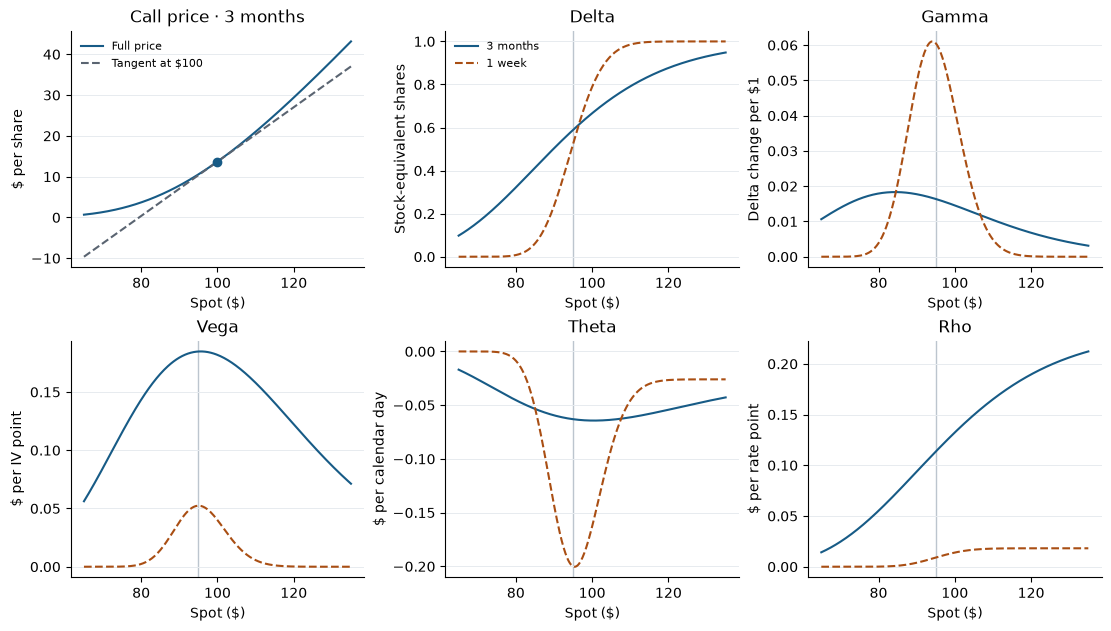

In [6]:
spots = np.linspace(65, 135, 281)
three_months = base | {"S": spots}
one_week = three_months | {"T": 7 / DAYS_PER_YEAR}
curves = [greeks(**three_months), greeks(**one_week)]
blue, orange = "#175b86", "#a94e13"

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), layout="constrained")
price_ax = axes.flat[0]
price_ax.plot(spots, price(**three_months), color=blue, label="Full price")
tangent = initial_price + initial_greeks["Delta"] * (spots - base["S"])
price_ax.plot(spots, tangent, color="#5a6471", linestyle="--", label="Tangent at $100")
price_ax.scatter(base["S"], initial_price, color=blue, zorder=4)
price_ax.set(xlabel="Spot ($)", ylabel="$ per share", title="Call price · 3 months")
price_ax.legend(frameon=False, fontsize=8)

labels = {
    "Delta": "Stock-equivalent shares",
    "Gamma": "Delta change per $1",
    "Vega": "$ per IV point",
    "Theta": "$ per calendar day",
    "Rho": "$ per rate point",
}
for ax, (name, units) in zip(list(axes.flat)[1:], labels.items()):
    ax.plot(spots, curves[0][name], color=blue, label="3 months")
    ax.plot(spots, curves[1][name], color=orange, linestyle="--", label="1 week")
    ax.axvline(base["K"], color="#bcc5ce", linewidth=1, zorder=0)
    ax.set(xlabel="Spot ($)", ylabel=units, title=name)
axes.flat[1].legend(frameon=False, fontsize=8)
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e7ebef", linewidth=0.7)
display(fig)
plt.close(fig)

## Lab 9 · Attribute P&L and stress a position

Return to the combined shock from class. Use today's Greeks for the estimate. Measure spot in dollars, IV and rates in percentage points, and time in days. The residual is the difference between full repricing and the estimate. It includes interactions between shocks and changes in the Greeks as inputs move.

$$
\Delta V\approx
\Delta\,\Delta S+\tfrac12\Gamma(\Delta S)^2
+\mathrm{Vega}\,\Delta \mathrm{IV}_{\mathrm{pp}}
+\Theta\,\mathrm{days}+\rho\,\Delta r_{\mathrm{pp}}.
$$

For a spot-only move, compare the delta-only and delta–gamma estimates with full repricing for a \$1 move and a \$15 move. What does the comparison say about using today's Greeks for a larger shock?

In [7]:
spot_shock = tomorrow["S"] - base["S"]
iv_points = (tomorrow["sigma"] - base["sigma"]) * 100
elapsed_days = (base["T"] - tomorrow["T"]) * DAYS_PER_YEAR
rate_points = (tomorrow["r"] - base["r"]) * 100
attribution = pd.Series({
    "Delta": initial_greeks["Delta"] * spot_shock,
    "Gamma": 0.5 * initial_greeks["Gamma"] * spot_shock**2,
    "Vega": initial_greeks["Vega"] * iv_points,
    "Theta": initial_greeks["Theta"] * elapsed_days,
    "Rho": initial_greeks["Rho"] * rate_points,
}, name="P&L ($ per option share)")

estimated = attribution.sum()
display(attribution.round(4).to_frame())
print(f"Greek estimate: {estimated:+.4f}")
print(f"Full repricing: {repriced:+.4f}")
print(f"Residual: {repriced - estimated:+.4f}")

new_delta = greeks(**tomorrow)["Delta"]
rebalance = -MULTIPLIER * (new_delta - initial_greeks["Delta"])
print(f"Hedge rebalance per contract: {rebalance:+.2f} shares (negative means sell)")

,P&L ($ per option share)
Delta,0.6665
Gamma,0.0073
Vega,-0.9092
Theta,-0.0643
Rho,0.0000


Greek estimate: -0.2998
Full repricing: -0.2825
Residual: +0.0173
Hedge rebalance per contract: -2.36 shares (negative means sell)


A straddle holds a call and put at the same strike and expiry. For each position, sum the signed Greeks across legs and multiply by the assumed contract size of 100 shares. Compare its spot exposure and vega with those of the single call. Then use the isolated and combined stresses to explain what drives position P&L.

In [8]:
straddle = [(1, base), (1, put)]
position_names = {
    "Long call": [(1, base)],
    "Long straddle": straddle,
}


def position_greeks(legs):
    leg_risk = [quantity * MULTIPLIER * pd.Series(greeks(**inputs)) for quantity, inputs in legs]
    return pd.concat(leg_risk, axis=1).sum(axis=1)


def position_value(legs, bumps):
    return sum(
        quantity * MULTIPLIER * price(**(inputs | {
            name: inputs[name] + change for name, change in bumps.items()
        }))
        for quantity, inputs in legs
    )


risk_report = pd.DataFrame({name: position_greeks(legs) for name, legs in position_names.items()}).T
display(risk_report.round(4))

scenarios = {
    "Spot down $10": {"S": -10.0},
    "Spot up $10": {"S": 10.0},
    "IV down 5 points": {"sigma": -0.05},
    "IV up 5 points": {"sigma": 0.05},
    "One calendar day passes": {"T": -1 / DAYS_PER_YEAR},
    "Rate up 1 point": {"r": 0.01},
    "Dividend yield up 1 point": {"q": 0.01},
    "Up $1, IV down 5 points, one day passes": {
        "S": 1.0, "sigma": -0.05, "T": -1 / DAYS_PER_YEAR,
    },
}
stress_report = pd.DataFrame({
    name: {scenario: position_value(legs, bumps) - position_value(legs, {})
           for scenario, bumps in scenarios.items()}
    for name, legs in position_names.items()
})
print("Full-repricing P&L in position dollars")
display(stress_report.round(2))

,Delta,Gamma,Vega,Theta,Rho
Long call,66.6465,1.4547,18.1843,-6.4327,13.2378
Long straddle,33.2930,2.9095,36.3687,-10.3270,3.3120


Full-repricing P&L in position dollars


,Long call,Long straddle
Spot down $10,-587.66,-175.31
Spot up $10,732.39,464.79
IV down 5 points,-90.52,-181.04
IV up 5 points,91.23,182.47
One calendar day passes,-6.45,-10.36
Rate up 1 point,13.27,3.40
Dividend yield up 1 point,-16.60,-8.22
"Up $1, IV down 5 points, one day passes",-28.25,-153.97


## Lab 9 · Simulate the delta hedge

Simulate stock paths to expiry under geometric Brownian motion with risk-neutral drift $r$. Set the stock's simulated volatility separately from the volatility used to value and hedge the call. Use the same random shocks across rebalancing schedules and both volatility cases so the comparisons are easier to interpret.

Hold a long call and short its delta in stock. Choose the initial cash balance so the position starts at zero value. Between hedge dates the balance earns or pays the risk-free rate. Each stock trade changes the cash balance by the cost or proceeds of that trade. At expiry, terminal P&L is cash plus the stock holding's value plus the call payoff. With matched volatilities it measures the terminal replication error of the discrete hedge. Mean P&L shows the average signed result and RMSE captures the size of the error.

The simulation assumes a non-dividend-paying stock, constant rates, fractional shares, and no transaction costs. One step is about 2.3 calendar days. The three schedules use the initial hedge only, eight hedge dates including inception, or 40 hedge dates including inception.

In [9]:
N_PATHS, N_STEPS, SEED = 4_000, 40, 9
dt = base["T"] / N_STEPS
draws = np.random.default_rng(SEED).standard_normal((N_PATHS, N_STEPS))


def simulate_paths(realized_vol):
    log_steps = (base["r"] - realized_vol**2 / 2) * dt + realized_vol * np.sqrt(dt) * draws
    paths = base["S"] * np.exp(np.cumsum(log_steps, axis=1))
    return np.column_stack((np.full(N_PATHS, base["S"]), paths))


def hedged_terminal_pnl(paths, rebalance_steps):
    shares = np.full(len(paths), -initial_greeks["Delta"])
    cash = -initial_price - shares * base["S"]
    cash_growth = np.exp(base["r"] * dt)

    for step in range(1, N_STEPS):
        cash *= cash_growth
        if step % rebalance_steps == 0:
            spot = paths[:, step]
            inputs = base | {"S": spot, "T": (N_STEPS - step) * dt}
            target_shares = -greeks(**inputs)["Delta"]
            cash -= (target_shares - shares) * spot
            shares = target_shares

    terminal_spot = paths[:, -1]
    payoff = np.maximum(terminal_spot - base["K"], 0)
    return cash * cash_growth + shares * terminal_spot + payoff


schedule = {"Initial hedge only": N_STEPS, "Every 5 steps": 5, "Every step": 1}
rows = []
for realized_vol in (base["sigma"], 0.65):
    paths = simulate_paths(realized_vol)
    for label, interval in schedule.items():
        pnl = hedged_terminal_pnl(paths, interval)
        rows.append({
            "Simulated volatility": f"{realized_vol:.0%}",
            "Rebalancing": label,
            "Mean P&L ($/share)": pnl.mean(),
            "RMSE ($/share)": np.sqrt(np.mean(pnl**2)),
            "5th percentile": np.quantile(pnl, 0.05),
            "95th percentile": np.quantile(pnl, 0.95),
        })

hedge_results = pd.DataFrame(rows).set_index(["Simulated volatility", "Rebalancing"])
display(hedge_results.round(4))

Mean P&L ($/share)  RMSE ($/share)  \
Simulated volatility Rebalancing                                              
50%                  Initial hedge only              0.0525          6.9555   
                     Every 5 steps                   0.0173          2.7497   
                     Every step                      0.0065          1.2541   
65%                  Initial hedge only              2.8431          9.5628   
                     Every 5 steps                   2.8207          4.7725   
                     Every step                      2.8224          3.4956   

                                         5th percentile  95th percentile  
Simulated volatility Rebalancing                                          
50%                  Initial hedge only         -8.2816          13.6713  
                     Every 5 steps              -4.4415           4.6731  
                     Every step                 -2.0464           2.0626  
65%                  Initial hedge only         -8.1638          20.3655  
                     Every 5 steps              -2.4438           9.8505  
                     Every step                  0.2833           6.7889

**Interpret the results.** With simulated volatility of 50%, how does rebalancing frequency change RMSE? At 65%, why can the long call and stock hedge earn positive average P&L when the hedger still uses 50%? Consider the value of large stock moves to a long-gamma position. Which result would you revisit first if trading the stock hedge had a cost?

**Submit.** Include a position Greek table and sensitivity charts, an analytical versus finite-difference check, and a combined-shock P&L attribution with its full-repricing residual. Use the isolated IV and aging stresses to explain vega and theta. Report the hedge error statistics and explain the effect of the volatility mismatch.

### Reading

- [Options Industry Council · Understanding Options Greeks](https://prd-web.optionseducation.org/advancedconcepts/understanding-options-greeks)
- [CME Group · Options Premium and the Greeks](https://www.cmegroup.com/education/courses/option-greeks/options-the-greeks-options-premium-and-the-greeks)